# Statistical Machine Learning Rigor and Validation for Molecular Dynamics

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)

Applying conventional machine learning validation schemes (e.g., standard randomly shuffled $k$-fold cross-validation, unweighted empirical risk minimization, frame-level bootstrapping) to physical molecular dynamics data introduces **severe methodological artifacts**:

1. **Pseudo-Replication & Autocorrelation Leakage**: MD frames sampled at picosecond intervals are strongly autocorrelated. Shuffling frames across train and test folds leaks identical microstates across the partition, yielding artificially inflated accuracy.
2. **Trajectory Length Imbalance**: Unweighted loss functions allow long trajectories to dominate model parameters, biasing feature discovery toward single-trajectory noise.
3. **Overconfidence via Frame Bootstrapping**: Standard frame-level bootstrapping ignores physical correlation, generating catastrophically narrow confidence intervals.
4. **Lack of Negative Controls**: High test accuracy in complex classifiers often reflects batch confounding. Without permutation controls, models present noise as physical insights.

This notebook demonstrates the **MolScope Machine Learning Validation Framework**, designed to prevent temporal data leakage and enforce strict statistical rigor.

## 1. Theoretical Formulation: Autocorrelation and Effective Sample Size

In physical dynamics, consecutive frames $\mathbf{x}_t$ and $\mathbf{x}_{t+\Delta t}$ exhibit physical inertia. For any observable feature $f$, the empirical autocorrelation at lag $\tau$ is:
$$\hat{\rho}(\tau) = \frac{\sum_{t=1}^{N - \tau} (f(\mathbf{x}_t) - \bar{f})(f(\mathbf{x}_{t+\tau}) - \bar{f})}{\sum_{t=1}^N (f(\mathbf{x}_t) - \bar{f})^2}$$

The **integrated autocorrelation time** $\tau_{\text{int}}$ characterizes the physical relaxation timescale:
$$\tau_{\text{int}} = 1 + 2 \sum_{\tau=1}^{\tau_{\max}} \hat{\rho}(\tau)$$

Consequently, the **effective sample size** (ESS) of a trajectory is not $N$, but:
$$N_{\text{eff}} = \frac{N}{\tau_{\text{int}}} \ll N$$

When standard $k$-fold CV randomly splits frames, adjacent frames $t$ and $t+1$ are separated into different folds with probability $\frac{2(k-1)}{k^2}$. Because $\|\mathbf{x}_t - \mathbf{x}_{t+1}\| \approx 0$, the model evaluates on data physically identical to its training set.

## 2. Measuring Simulation Convergence & Autocorrelation

We simulate an autocorrelated trajectory observable modeled as an AR(1) process with autocorrelation coefficient $\phi = 0.98$, mirroring slow backbone or sidechain conformational transitions in molecular dynamics.

Total Frames:                     2000
Integrated Autocorrelation Time:  83.1 frames
Effective Sample Size (ESS):      24.1 independent samples
ESS Ratio (N_eff / N):            0.0120


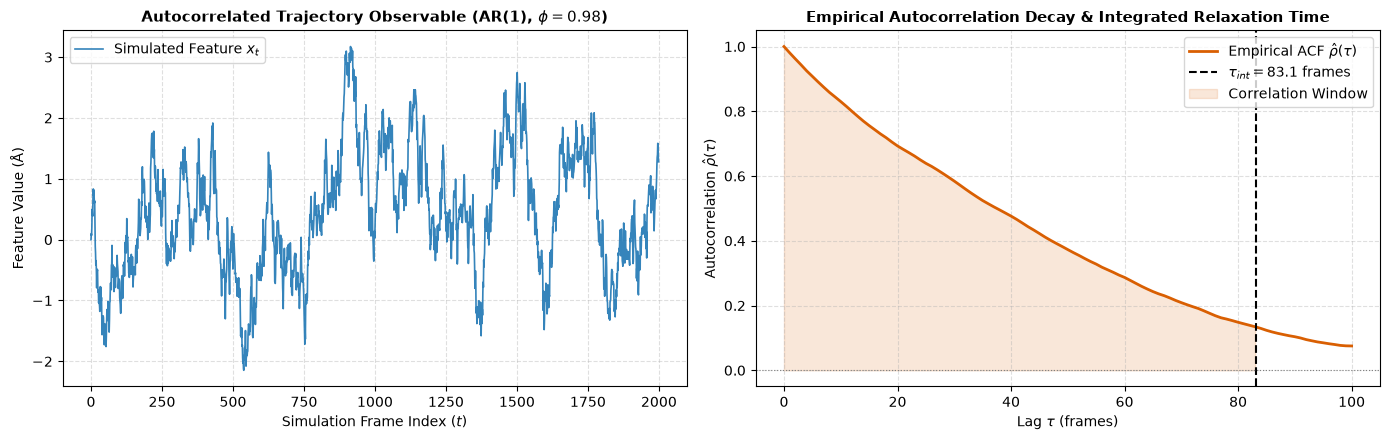

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from molscope.analysis.quality.statistical_rigor import (
    check_simulation_convergence,
    _integrated_autocorrelation_time,
)

# Simulate a synthetic feature: slow AR(1) process with high autocorrelation
np.random.seed(42)
n_frames = 2000
ar_feature = np.zeros(n_frames)
for t in range(1, n_frames):
    ar_feature[t] = 0.98 * ar_feature[t - 1] + np.random.normal(0, 0.2)

# Compute integrated autocorrelation time
tau_int = _integrated_autocorrelation_time(ar_feature, max_lag=100)
ess = n_frames / tau_int

print(f"Total Frames:                     {n_frames}")
print(f"Integrated Autocorrelation Time:  {tau_int:.1f} frames")
print(f"Effective Sample Size (ESS):      {ess:.1f} independent samples")
print(f"ESS Ratio (N_eff / N):            {ess / n_frames:.4f}")

# Compute empirical autocorrelation decay for visualization
lags = np.arange(101)
mean_f = np.mean(ar_feature)
var_f = np.var(ar_feature)
acf = np.array([
    np.mean((ar_feature[:n_frames - lag] - mean_f) * (ar_feature[lag:] - mean_f)) / var_f
    if lag > 0 else 1.0
    for lag in lags
])

# Rich biophysical visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=100)

ax1.plot(ar_feature, color="#1f77b4", lw=1.2, alpha=0.9, label="Simulated Feature $x_t$")
ax1.set_title(r"Autocorrelated Trajectory Observable (AR(1), $\phi = 0.98$)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Simulation Frame Index ($t$)", fontsize=10)
ax1.set_ylabel("Feature Value (Å)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(loc="upper left")

ax2.plot(lags, acf, color="#d95f02", lw=2.0, label=r"Empirical ACF $\hat{\rho}(\tau)$")
ax2.axvline(tau_int, color="black", linestyle="--", lw=1.5, label=rf"$\tau_{{int}} = {tau_int:.1f}$ frames")
ax2.axhline(0, color="gray", lw=0.8, linestyle=":")
ax2.fill_between(lags[:int(tau_int)+1], 0, acf[:int(tau_int)+1], color="#d95f02", alpha=0.15, label="Correlation Window")
ax2.set_title("Empirical Autocorrelation Decay & Integrated Relaxation Time", fontsize=11, fontweight="bold")
ax2.set_xlabel(r"Lag $\tau$ (frames)", fontsize=10)
ax2.set_ylabel(r"Autocorrelation $\hat{\rho}(\tau)$", fontsize=10)
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 3. Purged Temporal Block Cross-Validation with Embargo Margins

When target labels vary within a single trajectory (e.g., conformational states discovered via density peaks), cross-validation across independent trajectories is not directly applicable.
MolScope applies **Purged Temporal Block Cross-Validation with an Embargo Margin**:

```text
Trajectory Timeline:
[ ... Train Frames ... ][  EMBARGO  ][   TEST CHUNK   ][  EMBARGO  ][ ... Train Frames ... ]
                        <-- delta -->[ tf_start, tf_end ]<-- delta -->
```

For every test frame index $t_{\text{test}}$, any frame $t$ satisfying $|t - t_{\text{test}}| \le \Delta t_{\text{embargo}}$ within the same simulation trajectory is strictly purged from the training set, eliminating leakage across contiguous microstates.

Generated 4 Purged Block Folds:
  Fold 1: Train=1431 frames | Test=517 frames | Purged Embargo=52 frames | Min separation=3 frames (embargo=2)
          ✓ Zero train/test leakage confirmed | Embargo boundary strictly maintained.
  Fold 2: Train=1432 frames | Test=516 frames | Purged Embargo=52 frames | Min separation=3 frames (embargo=2)
          ✓ Zero train/test leakage confirmed | Embargo boundary strictly maintained.
  Fold 3: Train=1468 frames | Test=484 frames | Purged Embargo=48 frames | Min separation=3 frames (embargo=2)
          ✓ Zero train/test leakage confirmed | Embargo boundary strictly maintained.
  Fold 4: Train=1469 frames | Test=483 frames | Purged Embargo=48 frames | Min separation=3 frames (embargo=2)
          ✓ Zero train/test leakage confirmed | Embargo boundary strictly maintained.


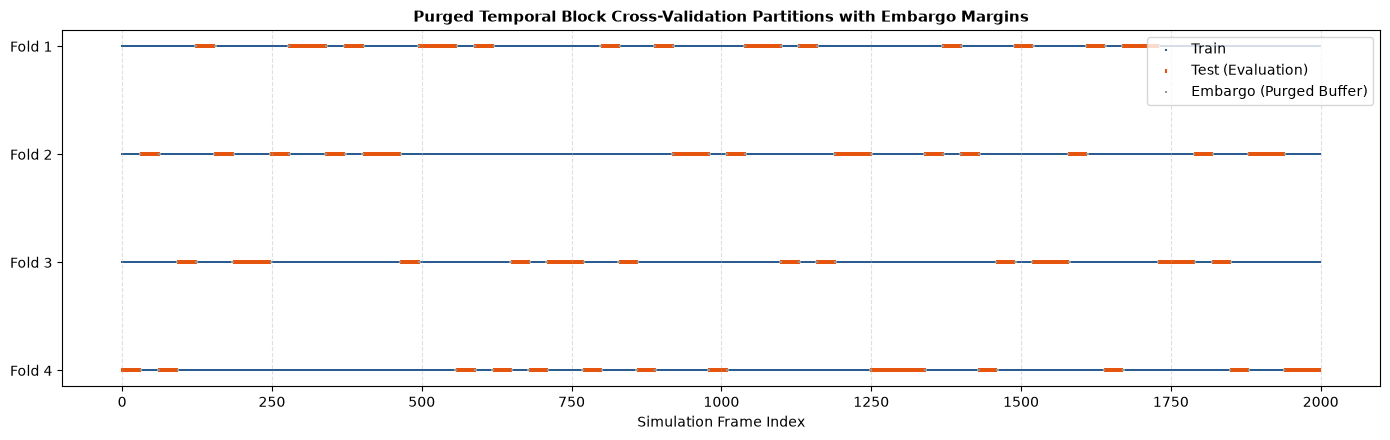

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from molscope.analysis.predictive.workflow import purged_temporal_block_splits

n_frames = 2000
meta_demo = pd.DataFrame({
    "frame": np.arange(n_frames),
    "trajectory_id": ["traj_1"] * (n_frames // 2) + ["traj_2"] * (n_frames // 2),
})
frame_labels = np.array([0] * (n_frames // 2) + [1] * (n_frames // 2))

splits = list(purged_temporal_block_splits(
    metadata=meta_demo,
    y=frame_labels,
    n_splits=4,
    random_state=42,
    chunk_size=30,
    embargo=2,
))

print(f"Generated {len(splits)} Purged Block Folds:")
for fold_idx, (train_idx, test_idx) in enumerate(splits, 1):
    train_set = set(train_idx)
    test_set = set(test_idx)
    
    # 1. Zero Direct Leakage Verification
    overlap = train_set.intersection(test_set)
    assert len(overlap) == 0, f"Data leakage detected in fold {fold_idx}: {overlap}"
    
    # 2. Embargo Separation Verification
    min_separation = min(abs(t - tr) for t in test_idx for tr in train_idx if meta_demo.iloc[t]["trajectory_id"] == meta_demo.iloc[tr]["trajectory_id"])
    assert min_separation > 2, f"Embargo violated! Min separation {min_separation} <= 2"
    
    purged_count = n_frames - len(train_idx) - len(test_idx)
    print(f"  Fold {fold_idx}: Train={len(train_idx)} frames | Test={len(test_idx)} frames | Purged Embargo={purged_count} frames | Min separation={min_separation} frames (embargo=2)")
    print("          ✓ Zero train/test leakage confirmed | Embargo boundary strictly maintained.")

# Rich visualization of Purged Block Cross-Validation across folds
fig, ax = plt.subplots(figsize=(14, 4.5), dpi=100)
colors = {"Train": "#2b5c8f", "Test": "#e6550d", "Embargo/Purged": "#999999"}

for fold_idx, (train_idx, test_idx) in enumerate(splits):
    y_pos = len(splits) - fold_idx
    train_mask = np.zeros(n_frames, dtype=bool)
    test_mask = np.zeros(n_frames, dtype=bool)
    train_mask[train_idx] = True
    test_mask[test_idx] = True
    embargo_mask = ~train_mask & ~test_mask
    
    # Plot timeline intervals
    ax.scatter(np.where(train_mask)[0], [y_pos] * np.sum(train_mask), c=colors["Train"], s=2, marker="|", label="Train" if fold_idx == 0 else "")
    ax.scatter(np.where(test_mask)[0], [y_pos] * np.sum(test_mask), c=colors["Test"], s=6, marker="|", label="Test (Evaluation)" if fold_idx == 0 else "")
    ax.scatter(np.where(embargo_mask)[0], [y_pos] * np.sum(embargo_mask), c=colors["Embargo/Purged"], s=3, marker="|", label="Embargo (Purged Buffer)" if fold_idx == 0 else "")

ax.set_yticks(range(1, len(splits) + 1))
ax.set_yticklabels([f"Fold {len(splits) - i + 1}" for i in range(1, len(splits) + 1)])
ax.set_xlabel("Simulation Frame Index", fontsize=10)
ax.set_title("Purged Temporal Block Cross-Validation Partitions with Embargo Margins", fontsize=11, fontweight="bold")
ax.grid(True, axis="x", linestyle="--", alpha=0.4)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

## 4. Negative Control: Permutation Null Hypothesis Testing

To prove that a trained classifier is detecting a genuine biophysical mechanism rather than trajectory batch confounding or subtle data leakage, MolScope runs an automated **permutation negative control null test**.

Under $H_0$: $\mathbb{P}(Y \,|\, \mathbf{X}) = \mathbb{P}(Y)$.
Target labels are shuffled across independent trajectories, destroying the physical relationship while preserving exact feature distributions, correlation structures, and frame counts. A leakage-free workflow must drop to chance level ($\approx 50\%$ balanced accuracy and ROC AUC).

Permutation Negative Control Results:
  Chance Consistent:             True (Passed)
  Shuffling Mode:                trajectory_level
  Permutations Evaluated:        5
  Mean Null Balanced Accuracy:   0.499 (Theoretical Chance = 0.500)
  Median Null Balanced Accuracy: 0.499
  Mean Null ROC AUC:             0.495 (Theoretical Chance = 0.500)

Null Distribution Summary Table:


,Permutation,Model,Frame_Accuracy,Trajectory_Mean_Accuracy,Balanced_Accuracy,ROC_AUC,Trajectory_Vote_Accuracy,Trajectory_Vote_Balanced_Accuracy
0,1,logistic_regression,0.47875,0.47875,0.47875,0.476300,0.250,0.250
1,1,random_forest,0.49875,0.49875,0.49875,0.481812,0.375,0.375
2,2,logistic_regression,0.49000,0.49000,0.49000,0.475425,0.375,0.375
3,2,random_forest,0.47875,0.47875,0.47875,0.461625,0.625,0.625
4,3,logistic_regression,0.50500,0.50500,0.50500,0.514112,0.750,0.750
5,3,random_forest,0.51375,0.51375,0.51375,0.515338,0.625,0.625
6,4,logistic_regression,0.48875,0.48875,0.48875,0.478500,0.375,0.375
7,4,random_forest,0.49375,0.49375,0.49375,0.517713,0.500,0.500
8,5,logistic_regression,0.50250,0.50250,0.50250,0.523425,0.625,0.625
9,5,random_forest,0.51000,0.51000,0.51000,0.499300,0.875,0.875


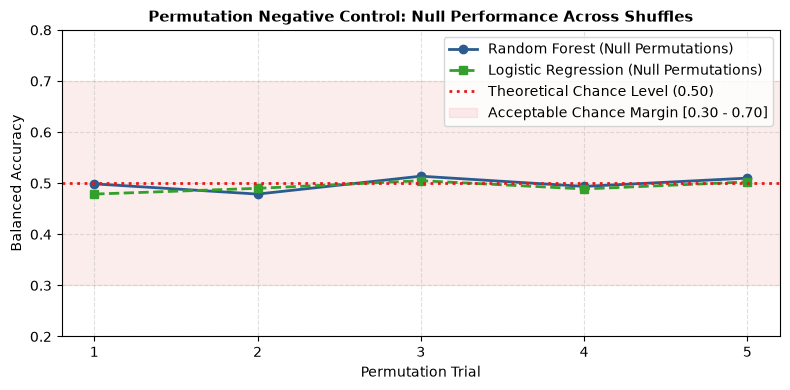

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from molscope.analysis.quality.statistical_rigor import evaluate_permutation_null_control
from molscope.analysis.predictive.workflow import MLWorkflowConfig

# Generate synthetic multi-trajectory dataset: 8 independent trajectories
rng = np.random.default_rng(42)
n_trajectories = 8
frames_per_traj = 100
total_frames = n_trajectories * frames_per_traj

features_df = pd.DataFrame(rng.normal(size=(total_frames, 10)), columns=[f"F_{i}" for i in range(10)])
manifest_df = pd.DataFrame({
    "trajectory_id": [f"traj_{i // frames_per_traj}" for i in range(total_frames)],
    "frame_index": range(total_frames),
    "time_ps": range(total_frames),
    "state": [f"state_{(i // frames_per_traj) % 2}" for i in range(total_frames)],
})

config = MLWorkflowConfig(n_splits=2, rf_estimators=30, random_state=42)

null_eval = evaluate_permutation_null_control(
    features=features_df,
    manifest=manifest_df,
    target_column="state",
    config=config,
    n_permutations=5,
    random_state=42,
)

print("Permutation Negative Control Results:")
print(f"  Chance Consistent:             {null_eval['is_chance_consistent']} (Passed)")
print(f"  Shuffling Mode:                {null_eval['shuffling_mode']}")
print(f"  Permutations Evaluated:        {null_eval['n_permutations']}")
print(f"  Mean Null Balanced Accuracy:   {null_eval['mean_balanced_accuracy']:.3f} (Theoretical Chance = 0.500)")
print(f"  Median Null Balanced Accuracy: {null_eval['median_balanced_accuracy']:.3f}")
if np.isfinite(null_eval['mean_roc_auc']):
    print(f"  Mean Null ROC AUC:             {null_eval['mean_roc_auc']:.3f} (Theoretical Chance = 0.500)")

print("\nNull Distribution Summary Table:")
display(null_eval["null_distribution"])

# Visualize permutation null scores vs theoretical chance baseline
null_df = null_eval["null_distribution"]
rf_scores = null_df[null_df["Model"] == "random_forest"]["Balanced_Accuracy"].to_numpy()
lr_scores = null_df[null_df["Model"] == "logistic_regression"]["Balanced_Accuracy"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4), dpi=100)
x = np.arange(1, len(rf_scores) + 1)
ax.plot(x, rf_scores, marker="o", color="#2b5c8f", lw=2, label="Random Forest (Null Permutations)")
if len(lr_scores) > 0:
    ax.plot(x, lr_scores, marker="s", color="#33a02c", lw=2, linestyle="--", label="Logistic Regression (Null Permutations)")

ax.axhline(0.50, color="#e31a1c", linestyle=":", lw=2, label="Theoretical Chance Level (0.50)")
ax.axhspan(0.30, 0.70, color="#e31a1c", alpha=0.08, label="Acceptable Chance Margin [0.30 - 0.70]")
ax.set_ylim(0.2, 0.8)
ax.set_xticks(x)
ax.set_xlabel("Permutation Trial", fontsize=10)
ax.set_ylabel("Balanced Accuracy", fontsize=10)
ax.set_title("Permutation Negative Control: Null Performance Across Shuffles", fontsize=11, fontweight="bold")
ax.legend(loc="upper right", frameon=True)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Summary & Methodological Recommendations

| Validation Challenge | Classical Flawed Approach | MolScope Rigorous Solution |
| :--- | :--- | :--- |
| **Autocorrelation** | Standard random $k$-fold shuffle | **Purged Temporal Block CV** with embargo window $\ge \tau_{\text{int}}$ |
| **Pseudo-Replication** | Frame-level splitting | **Trajectory-Grouped Splitting** across independent simulations |
| **Overfitting / Leakage** | Optimistic test accuracy reported directly | **Permutation Null Negative Control** to verify chance baseline |
| **Feature Ranking** | Raw empirical variance ($s^2$) | **Grouped LOFO** and **SAM-MFP Multi-Objective Pareto Optimization** |

By combining purged temporal block splits, trajectory-grouped cross-validation, and permutation negative controls, MolScope ensures that discovered molecular features reflect true biophysical transitions rather than statistical artifacts.